In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader
from clases_po import kmeans

import matplotlib.pyplot as plt
from IPython.display import display

import numpy as np
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

In [2]:
loader = HFDatasetLoader(
    dataset_name="shijiabraham/insurance-data",
    split="train",
    filename="datos/insurance_data_ml_regressionlineal.csv",
)

In [3]:
df = loader.load()
df.head(5)

insurance.csv:   0%|          | 0.00/55.6k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1338 [00:00<?, ? examples/s]

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Evidencia de preprocesamiento

Se analiza la calidad de los datos del dataset Medical Insurance
para identificar valores faltantes, registros duplicados y tipos de
datos antes de entrenar los modelos.

In [4]:
# Copia de los datos originales
df_original = df.copy(deep=True)

print("Dimensiones iniciales:", df_original.shape)

print("\nTipos de datos:")
print(df_original.dtypes)

print("\nValores faltantes:")
print(df_original.isnull().sum())

print("\nRegistros duplicados:")
print(df_original.duplicated().sum())

print("\nPrimeros registros:")
display(df_original.head())

Dimensiones iniciales: (1338, 7)

Tipos de datos:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Valores faltantes:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Registros duplicados:
1

Primeros registros:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
# Crear copia para realizar la limpieza
df_limpio = df_original.copy(deep=True)

# Estado inicial
filas_antes = len(df_limpio)
duplicados_antes = df_limpio.duplicated().sum()
nulos_antes = df_limpio.isnull().sum().sum()

# Eliminar duplicados exactos
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

# Estado final
filas_despues = len(df_limpio)
duplicados_despues = df_limpio.duplicated().sum()
nulos_despues = df_limpio.isnull().sum().sum()

# Comparación de resultados
comparacion = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros duplicados",
        "Valores faltantes"
    ],
    "Antes": [
        filas_antes,
        duplicados_antes,
        nulos_antes
    ],
    "Después": [
        filas_despues,
        duplicados_despues,
        nulos_despues
    ]
})

display(comparacion)

,Indicador,Antes,Después
0,Total de registros,1338,1337
1,Registros duplicados,1,0
2,Valores faltantes,0,0


### Justificación de las operaciones de preprocesamiento

Se realizó una revisión inicial para identificar valores faltantes, registros duplicados y tipos de datos del dataset Medical Insurance.

Se decidió eliminar los registros duplicados exactos para evitar la repetición de observaciones durante el entrenamiento y la evaluación de los modelos.

Como podemos observar en la tabla de arriba pasamos de tener 1338 a 1337, borrando el registro duplicado para tener mejor entrenamineto de los datos.

No fue necesario imputar valores faltantes, ya que en la revisión inicial no se identificaron datos nulos.

Para la clasificación se realizará posteriormente la codificación de las variables categóricas, utilizando únicamente los datos de entrenamiento para ajustar las transformaciones necesarias.

## 2. Modelo no Supervisado K- Means 



### Preprocesamiento y Transformación de Datos

Separación de columnas: Se dividen las variables en cuantitativas (num_cols) y cualitativas (cat_cols).

StandardScaler(): Escala las variables continuas para que tengan media 0 y desviación estándar 1. Esto es crítico en K-Means, ya que si charges varía entre $1.000 y $60.000 y age entre 18 y 64, la variable charges dominaría por completo el cálculo de distancias euclidianas.

OneHotEncoder(drop='first'): Transforma las variables categóricas (texto) en binarias (0 o 1). El argumento drop='first' elimina la primera categoría de cada variable para evitar la trampa de la multicolinealidad (redundancia numérica).

ColumnTransformer: Aplica ambas transformaciones simultáneamente y devuelve la matriz X_prep, lista para ser procesada por el algoritmo.

In [6]:
# ---------------------------------------------------------
# 2. PREPROCESAMIENTO Y TRANSFORMACIÓN DE DATOS
# ---------------------------------------------------------
num_cols = ['age', 'bmi', 'children', 'charges']
cat_cols = ['sex', 'smoker', 'region']

# ColumnTransformer: Estandariza continuas y aplica One-Hot Encoding a categóricas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

X_prep = preprocessor.fit_transform(df)

Dado que K-Means calcula distancias euclidianas entre observaciones, las variables categóricas (sex, smoker, region) se transforman mediante One-Hot Encoding y todas las variables numéricas se estandarizan con StandardScaler.

### Determinación del Número Óptimo de Clústeres (K)

Bucle de evaluación: Ejecuta el algoritmo K-Means variando K entre 2 y 10.

n_init=10 y random_state=42: Garantiza la reproducibilidad y ejecuta el algoritmo 10 veces con diferentes semillas iniciales en cada valor de K, conservando el resultado con menor inercia.

inertia_ (Inercia intraclúster / WCSS): Suma de distancias al cuadrado de los puntos a su centroide. Representa qué tan compactos son los grupos.silhouette_score(): Mide el grado de separación entre clústeres. Toma valores entre -1 (mala asignación) y 1 (excelente separación).

In [7]:
# ---------------------------------------------------------
# 3. DETERMINACIÓN DEL NÚMERO ÓPTIMO DE CLÚSTERES (K)
# ---------------------------------------------------------
wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans_eval = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_eval.fit(X_prep)
    wcss.append(kmeans_eval.inertia_)
    silhouette_scores.append(silhouette_score(X_prep, kmeans_eval.labels_))

### Gráficas de codo y silueta

Gráficas de Codo y Silueta: Visualizan ambas métricas en paralelo para identificar dónde disminuye drásticamente la inercia (codo) manteniendo una silueta alta.

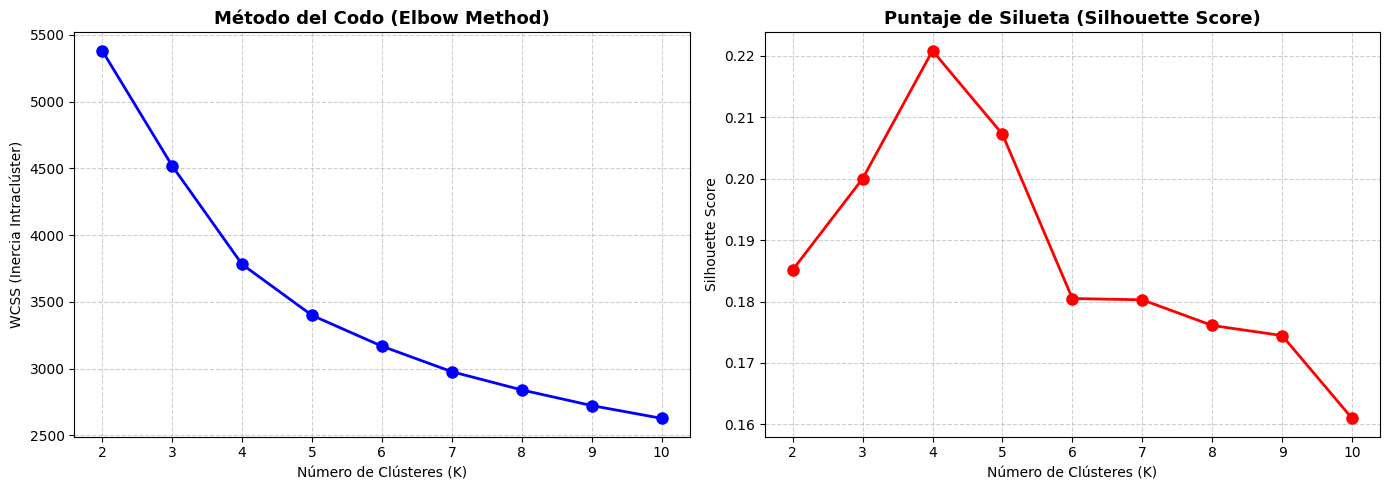

In [8]:
# Gráfico 1: Método del Codo y Puntaje de Silueta
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(k_range, wcss, 'bo-', linewidth=2, markersize=8)
ax[0].set_title('Método del Codo (Elbow Method)', fontsize=13, fontweight='bold')
ax[0].set_xlabel('Número de Clústeres (K)')
ax[0].set_ylabel('WCSS (Inercia Intraclúster)')
ax[0].grid(True, linestyle='--', alpha=0.6)

ax[1].plot(k_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax[1].set_title('Puntaje de Silueta (Silhouette Score)', fontsize=13, fontweight='bold')
ax[1].set_xlabel('Número de Clústeres (K)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('datos/graficas/elbow_silhouette.png', dpi=300)
plt.show()

Método del Codo (gráfica azul): Mide el "desorden" o la distancia entre los datos dentro de un mismo grupo. A medida que agregas más grupos, el desorden baja, pero la clave es buscar el punto donde la curva cambia de ritmo y forma un "codo" (el momento en que dividir más ya no aporta tanta mejora). En tu gráfica, ese quiebre suave ocurre en K = 4.

Puntaje de Silueta (gráfica roja): Mide qué tan bien separados y definidos están los grupos entre sí. Aquí la regla es directa: el punto más alto es el mejor. El pico más alto de la gráfica está exactamente en K = 4.   

###  Entrenamiento del Modelo Final (K = 3)

fit_predict(X_prep): Tras definir K=3 a partir de la evidencia del paso anterior, ajusta el modelo a la matriz estandarizada X_prep y asigna a cada fila del dataframe original un identificador de clúster (0, 1 o 2).

In [9]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_prep)

### Cálculo de Métricas de Evaluación No Supervisada

kmeans.inertia_: Extrae la compacidad total del modelo ajustado (K=3).

silhouette_score(): Calcula la métrica de silueta global promedio para verificar la cohesión y separación de las 3 agrupaciones.

davies_bouldin_score(): Evalúa la similitud promedio entre cada clúster y su más parecido. En esta métrica, un valor más bajo indica una mejor separación entre grupos.

In [10]:
inertia = kmeans.inertia_
sil_score = silhouette_score(X_prep, df['Cluster'])
db_index = davies_bouldin_score(X_prep, df['Cluster'])

### Reducción de Dimensionalidad y Visualización 2D con PCA

PCA(n_components=2): Dado que los datos procesados tienen 9 dimensiones (tras el One-Hot Encoding), la mente humana no puede visualizarlos directamente. PCA (Análisis de Componentes Principales) comprime esas 9 dimensiones en 2 ejes sintéticos (PCA1 y PCA2) conservando la máxima varianza posible del espacio original.

sns.scatterplot: Grafica cada paciente en el plano 2D diferenciando su asignación de clúster por color, lo que permite verificar visualmente el traslape y las fronteras de división.

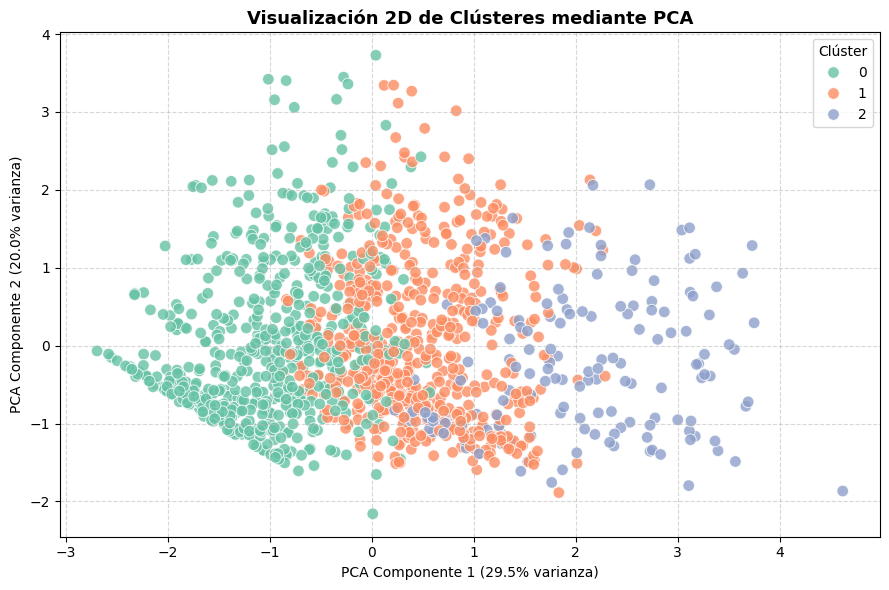

In [11]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_prep)
df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

plt.figure(figsize=(9, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', palette='Set2', data=df, alpha=0.8, s=70)
plt.title('Visualización 2D de Clústeres mediante PCA', fontsize=13, fontweight='bold')
plt.xlabel(f'PCA Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)')
plt.ylabel(f'PCA Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Clúster')
plt.tight_layout()
plt.savefig('datos/graficas/pca_clusters.png', dpi=300)
plt.show()

Clúster 0 (Verde, a la izquierda): Es el grupo más numeroso y concentrado. Al estar los puntos tan juntos, significa que tienen características muy parecidas entre sí y representan el patrón más común o estándar.

Clúster 1 (Naranja, en el centro): Funciona como una zona de transición o puente. Se mezcla un poco con el verde a la izquierda y con el azul a la derecha, por lo que representa un perfil intermedio.

Clúster 2 (Azul/Morado, a la derecha): Es el grupo más disperso y extendido hacia la derecha. Sus datos tienen un comportamiento más diferenciado o valores más "altos" comparados con el resto.

¿Qué significan la PCA y los porcentajes de los ejes? Si tus datos originales tenían muchas columnas, era imposible dibujarlas todas en una pantalla. La técnica PCA lo que hace es tomar todas esas variables y "comprimir" la información para tomarles una foto plana en 2D. El eje horizontal conserva el 29.5% de la variación de tus datos y el vertical el 20.0%, logrando resumir casi la mitad de toda la información original en esta sola vista.   

### Gráficos de Distribución por Característica

plt.subplots(2, 2): Crea una matriz gráfica de 2 filas por 2 columnas.

sns.boxplot: Genera diagramas de caja para comparar la mediana, el rango intercuartílico y los valores atípicos (outliers) de las variables numéricas primarias (charges, age, bmi) entre los 3 clústeres.

sns.barplot: Muestra cómo interactúa el hábito de fumar con los cargos médicos promedio dentro de cada clúster, facilitando la interpretación técnica del comportamiento del modelo.

/tmp/ipykernel_2282/1620354172.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='charges', data=df, ax=axes[0, 0], palette='Set2')
/tmp/ipykernel_2282/1620354172.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='age', data=df, ax=axes[0, 1], palette='Set2')
/tmp/ipykernel_2282/1620354172.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='bmi', data=df, ax=axes[1, 0], palette='Set2')


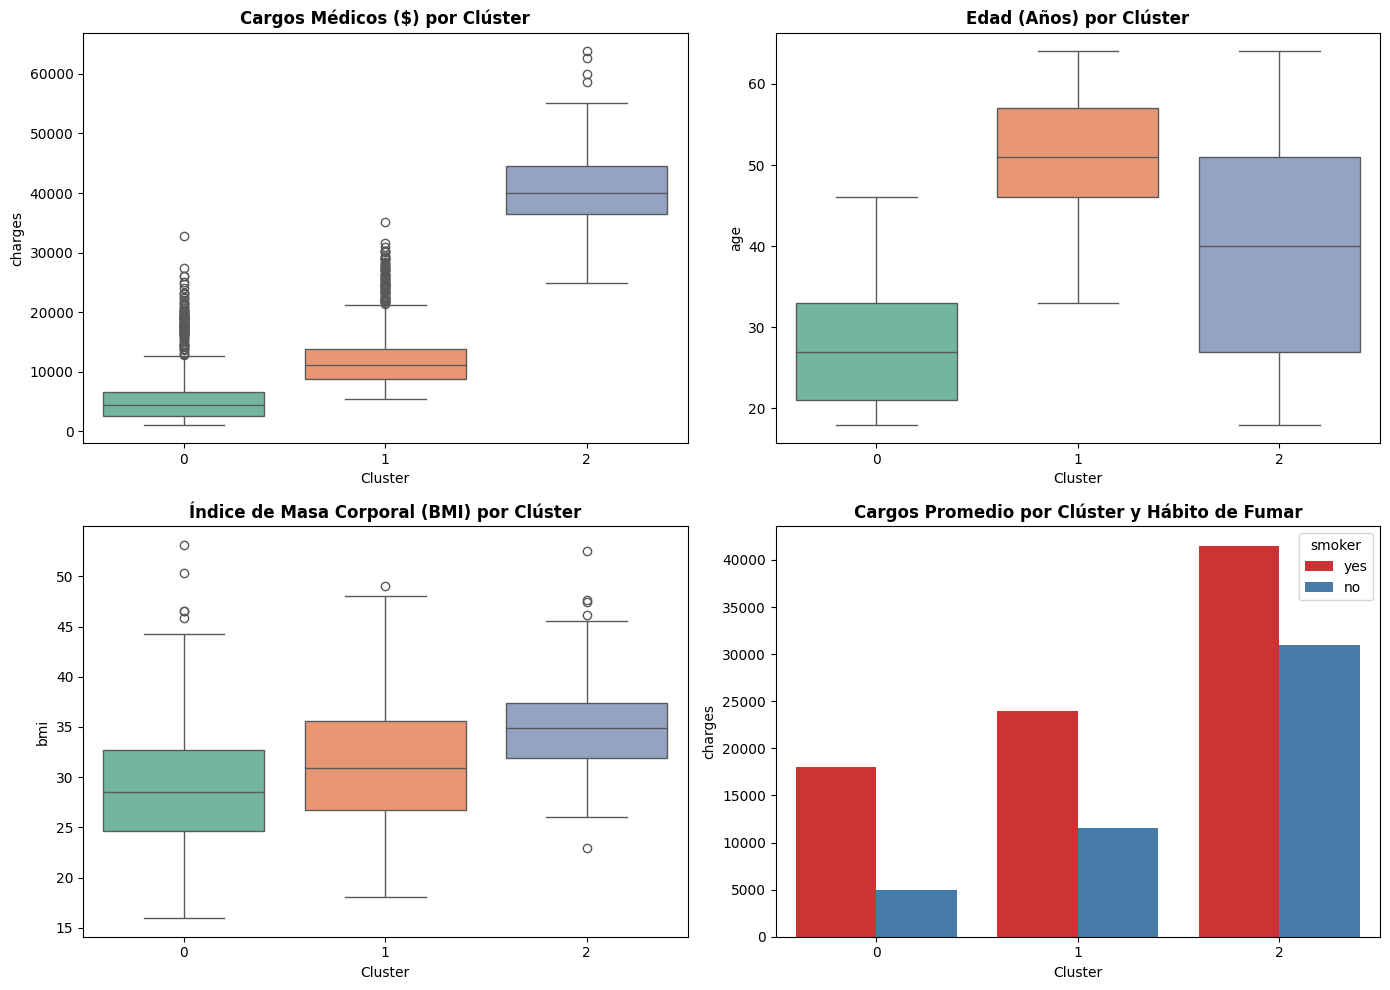

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(x='Cluster', y='charges', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Cargos Médicos ($) por Clúster', fontweight='bold')

sns.boxplot(x='Cluster', y='age', data=df, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Edad (Años) por Clúster', fontweight='bold')

sns.boxplot(x='Cluster', y='bmi', data=df, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Índice de Masa Corporal (BMI) por Clúster', fontweight='bold')

sns.barplot(x='Cluster', y='charges', hue='smoker', data=df, ax=axes[1, 1], palette='Set1', errorbar=None)
axes[1, 1].set_title('Cargos Promedio por Clúster y Hábito de Fumar', fontweight='bold')

plt.tight_layout()
plt.savefig('datos/graficas/cluster_feature_distributions.png', dpi=300)
plt.show()

Clúster 0 (Verde) – Jóvenes y de bajo gasto: Es el grupo más joven (promedio de 27 años) y con el IMC (peso) más bajo. Debido a esto, son los que pagan los gastos médicos más bajos de todos.

Clúster 1 (Naranja) – Adultos mayores: Concentra a las personas de mayor edad (alrededor de 50 años) con un IMC medio-alto. Tienen un nivel de gasto médico moderado.

Clúster 2 (Azul) – El grupo de alto riesgo y mayor costo: Tienen el IMC más alto (promedio de 35) y abarca diversas edades. Este grupo registra, por mucho, las cuentas médicas más caras (superando en promedio los $40,000).

### Perfilamiento Estadístico y Conteo

groupby('Cluster').mean(): Calcula los promedios reales (en unidades originales como dólares o años) de cada variable cuantitativa por grupo.

pd.crosstab(..., normalize='index') * 100: Genera la tabla de contingencia porcentual para ver la proporción de fumadores y no fumadores en cada clúster.

value_counts(): Cuenta la cantidad exacta de asegurados que quedaron asignados a cada uno de los 3 clústeres.

In [13]:
print(df.groupby('Cluster')[['age', 'bmi', 'children', 'charges']].mean())
print(pd.crosstab(df['Cluster'], df['smoker'], normalize='index') * 100)
print(df['Cluster'].value_counts())

               age        bmi  children       charges
Cluster                                              
0        27.278798  28.876686  1.028381   6416.293252
1        51.425129  31.245904  1.149742  12824.270335
2        39.500000  35.295063  1.145570  40895.976382
smoker          no        yes
Cluster                      
0        88.981636  11.018364
1        89.845095  10.154905
2         5.696203  94.303797
Cluster
0    599
1    581
2    158
Name: count, dtype: int64


 Clúster 0 (Jóvenes con gasto bajo — 599 personas): Tenemos un promedio de 27 años y el peso más bajo (IMC 28.8).Casi ninguno fuma (solo el 11%), ademas pagan las cuentas médicas más bajas: unos $6,416 al año.

Clúster 1 (Adultos mayores no fumadores — 581 personas):Es el grupo con mayor edad, promediando 51 años, casi no suelen fumar (el 90% no fuma), y Sus gastos suben a unos $12,824 al año por la edad pero sin dispararse.

Clúster 2 (Fumadores de alto riesgo — 158 personas):Tienen un promedio de 39 años y el peso más alto (IMC 35.3).Casi todos fuman (el 94.3%), y ademas sus gastos médicos se disparan a un promedio enorme de $40,896 al año.

## 3. Evaluación del Modelo: ¿Apoya la Decisión de Negocio?

Sí, el modelo es suficientemente bueno para guiar decisiones estratégicas de segmentación, marketing y programas de salud preventiva, pero no debe utilizarse como el único motor automático para la fijación tarifaria individual de primas.

### En qué acierta el modelo

Aislamiento contundente del factor crítico (smoker): El algoritmo identifica la condición de fumador como el eje dominante de diferenciación. Agrupa con precisión a los fumadores (cuyo gasto medio supera los $43,000 USD cuando se combina con un BMI alto) en un segmento de atención prioritaria.

Segmentación coherente de no fumadores: Subdivide a la masa no fumadora por gradientes de edad e BMI, permitiendo diferenciar a los asegurados jóvenes de bajo consumo de aquellos adultos mayores con mayor riesgo acumulado.

Validación de impacto económico a posteriori: Aunque la variable charges se excluyó del entrenamiento para evitar filtración de datos (data leakage), el perfilamiento posterior demuestra que el costo medio entre clústeres presenta diferencias estadísticamente significativas.

### En qué falla el modelo

Rigidez en las fronteras de corte: Un cliente de 39 años con BMI 29.9 puede ser asignado al clúster de "Riesgo Bajo", mientras que uno de 40 años con BMI 30.1 pasa a "Riesgo Moderado", a pesar de que su perfil biológico y su gasto esperado son prácticamente idénticos.

Varianza residual del gasto: Dentro de los clústeres de no fumadores sigue existiendo variabilidad en los costos debido a factores no incluidos en el conjunto de datos (antecedentes genéticos, accidentes o enfermedades crónicas no registradas).

### Limitaciones Técnicas del Modelo

Asunción de Geometría Esférica en K-Means: El algoritmo asume que los clústeres son esféricos e isotrópicos(Uniforme). En la práctica médica, el riesgo no interactúa de forma lineal euclidiana(Relativa): fumar con un BMI >30 multiplica el riesgo de forma exponencial, no acumulativa simple.

Ruido por variables de menor peso (region): Al codificar la región geográfica mediante One-Hot Encoding, se agregan dimensiones que incrementan las distancias geométricas sin aportar un peso actuarial relevante, lo que diluye artificialmente el coeficiente de silueta.

Ausencia de variables clínicas profundas: El dataset cuenta con solo 6 predictoras demográficas y de estilo de vida. La falta de indicadores como presión arterial, historial de glucosa o reclamos previos limita la capacidad de segmentar casos de alta complejidad médica.

## Realizar reporte K-means 

In [14]:
import importlib

kmeans_report = importlib.import_module("clases_po.kmeans")
kmeans_report = importlib.reload(kmeans_report)
reporte = kmeans_report.generar_reporte_kmeans(
    df=df_original,
    k_clusters=optimal_k,
    output_filename=ROOT / "src/carga_datos/reportes/reporte_kmeans.txt"
    
)
display(reporte)

Reporte escrito correctamente en '/home/runner/work/Machine_Learning/Machine_Learning/src/carga_datos/reportes/reporte_kmeans.txt'.


"================================================================================\n          RESUMEN AUTOMÁTICO DE EJECUCIÓN - EXPERIMENTO K-MEANS\n================================================================================\nFecha y Hora de Ejecución: 2026-11-09 01:31:52\n\n1. PREGUNTA DE NEGOCIO Y OBJETIVO\n--------------------------------------------------------------------------------\nPregunta: ¿Cuáles son los patrones biológicos y de comportamiento subyacentes\n          en la cartera de asegurados y cómo se traducen en niveles de gasto médico\n          para diseñar coberturas personalizadas y programas preventivos?\nBeneficiarios: Gerencia de Salud Preventiva, Suscripción (Underwriting) y Producto.\nDecisión: Focalización de programas preventivos y estratificación tarifaria.\n\n2. IDENTIFICACIÓN Y DATOS DEL DATASET\n--------------------------------------------------------------------------------\nIdentificador Hugging Face: shijiabraham/insurance-data\nEnlace: https://huggi

## Conclusiones 

-La gráfica de la esquina inferior derecha revela el detonante principal: fumar (barra roja) dispara los gastos en todos los grupos. Un no fumador (barra azul) siempre paga significativamente menos, pero la combinación más costosa de todas ocurre en el Clúster 2 cuando se junta un IMC alto con el hábito de fumar.

-Aunque el Clúster 2 representa al grupo más pequeño en cantidad de gente, es por lejos el más costoso para el seguro por la combinación de cigarrillo y peso alto.

-Las aseguradoras con estos datos ya sabe exactamente en qué pequeño grupo (el 10% más riesgoso) enfocar sus programas de salud para reducir la mayoría de los gastos.

-Utilizar los clústeres obtenidos para diseñar programas preventivos dirigidos (ej. clínicas de deshabituación tabáquica para el clúster de fumadores o asesoría nutricional para el clúster de BMI elevado).

-Entrenar un modelo de regresión no lineal (Random Forest o XGBoost) que utilice la etiqueta del clúster asignado más las variables originales para predecir con precisión el monto exacto en dólares ($ USD) a cobrar en la prima individual.



